# Summary of the SR-enriched fib MC2020 models

Run the statistics notebooks of each folder first.

In [1]:
import json
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams.update({
                        'font.family': 'serif',
                        'mathtext.fontset': 'cm',
                        'axes.unicode_minus': False
                    })
import numpy as np
import pandas as pd
import seaborn as sns
import scipy as sci
from sklearn.metrics import r2_score

In [2]:
# Results exported by the statistics notebooks of each folder
models = {
            'fib MC2020':                     ('fib2020/statistics_original_model_results.xlsx', None),
            'fib MC2020 + SR (Dataset 1)':    ('fib2020/statistics_pysr_dataset1_results.xlsx', 'fib2020-dataset1'),
            'Proposal 1':                     ('fib2020ts-dataset1/statistics_original_model_results.xlsx', None),
            'Proposal 1 + SR (Dataset 1)':    ('fib2020ts-dataset1/statistics_pysr_dataset1ts_results.xlsx', 'fib2020ts-dataset1'),
            'Proposal 1 + SR (Dataset 2)':    ('fib2020ts-dataset2/statistics_pysr_dataset2ts_results.xlsx', 'fib2020ts-dataset2'),
         }
results = {k: pd.read_excel(v[0]) for k, v in models.items()}

### Summary table

In [3]:
rows = []
for k, df in results.items():
    obs, pred, ratio = df['w_exp'], df['wnum'], df['wnum/wexp']
    big = obs > 0.4
    row = {'model': k}
    folder = models[k][1]
    if folder:
        with open(f'../train_symbolic_regression/{folder}/selected_model.json', 'r', encoding='utf-8') as f:
            sel = json.load(f)
        row.update({'complexity': sel['complexity'], 'score': sel['score'], 'R2 train (SR)': sel['train_r2'], 'R2 test (SR)': sel['test_r2']})
    row.update({
                'R2': r2_score(obs, pred),
                'RMSE (mm)': np.sqrt(np.mean((pred - obs) ** 2)),
                'mean wnum/wexp': ratio.mean(),
                'std wnum/wexp': ratio.std(),
                'CoV': ratio.std() / ratio.mean(),
                'mean wnum/wexp (w_exp > 0.4)': ratio[big].mean(),
                'bias w_exp > 0.4 (mm)': np.mean((pred - obs)[big]),
               })
    for dist_name in ['norm', 't', 'lognorm']:
        dist = getattr(sci.stats, dist_name)
        row[f'KS p {dist_name}'] = sci.stats.kstest(ratio.values, dist.cdf, args=dist.fit(ratio.values)).pvalue
    rows.append(row)
summary = pd.DataFrame(rows).set_index('model')
summary.to_excel('summary_sr_models.xlsx')
summary.round(3).T

model,fib MC2020,fib MC2020 + SR (Dataset 1),Proposal 1,Proposal 1 + SR (Dataset 1),Proposal 1 + SR (Dataset 2)
R2,0.422,0.832,0.391,0.816,0.820
RMSE (mm),0.087,0.047,0.090,0.049,0.049
mean wnum/wexp,0.857,1.024,1.054,1.056,1.045
std wnum/wexp,0.249,0.193,0.368,0.190,0.195
CoV,0.291,0.189,0.349,0.180,0.186
mean wnum/wexp (w_exp > 0.4),0.686,0.932,0.855,0.928,0.929
bias w_exp > 0.4 (mm),-0.178,-0.038,-0.086,-0.039,-0.039
KS p norm,0.200,0.019,0.005,0.149,0.543
KS p t,0.258,0.286,0.031,0.256,0.543
KS p lognorm,0.811,0.158,0.513,0.576,0.639


# Paper figures

Shaded areas: empirical KDE. Dashed lines: fitted log-normal distribution.

In [4]:
cm = 1 / 2.54
dpi = 600
colors = {'original': '#1f4e9a', 'sr1': '#c0392b', 'sr2': '#1e8449'}

def scatter(ax, df, title, color):
    lims = [0.0, 0.85]
    ax.plot(lims, lims, linewidth=2, linestyle='--', color='black')
    ax.scatter(df['w_exp'], df['wnum'], alpha=0.3, color=color, s=12)
    ax.text(0.04, 0.92, rf"$R^2$ = {r2_score(df['w_exp'], df['wnum']):.2f}", transform=ax.transAxes, fontsize=11)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel('Observed $w_{exp}$ (mm)', fontsize=11)
    ax.set_ylabel('Predicted $w_{num}$ (mm)', fontsize=11)
    ax.set_title(title, fontsize=11)
    ax.grid(True, linewidth=0.3)

def kde(ax, items):
    x = np.linspace(0.0, 2.5, 500)
    for label, df, color in items:
        ratio = df['wnum/wexp'].values
        sns.kdeplot(x=ratio, fill=True, alpha=0.15, color=color, ax=ax, label=label)
        mean, std = ratio.mean(), ratio.std(ddof=1)
        sigma = np.sqrt(np.log(1 + (std / mean) ** 2))
        mu = np.log(mean) - 0.5 * sigma ** 2
        ax.plot(x, sci.stats.lognorm.pdf(x, s=sigma, scale=np.exp(mu)), linestyle='--', linewidth=1.2, color=color)
    ax.axvline(1.0, color='gray', linewidth=0.8)
    ax.set_xlim(0.0, 2.5)
    ax.set_xlabel('$w_{num}/w_{exp}$', fontsize=11)
    ax.set_ylabel('Density', fontsize=11)
    handles, labels = ax.get_legend_handles_labels()
    handles.append(mpl.lines.Line2D([], [], color='black', linestyle='--', linewidth=1.2))
    labels.append('Log-normal fit')
    ax.legend(handles, labels, fontsize=9, loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
    ax.grid(True, linewidth=0.3)

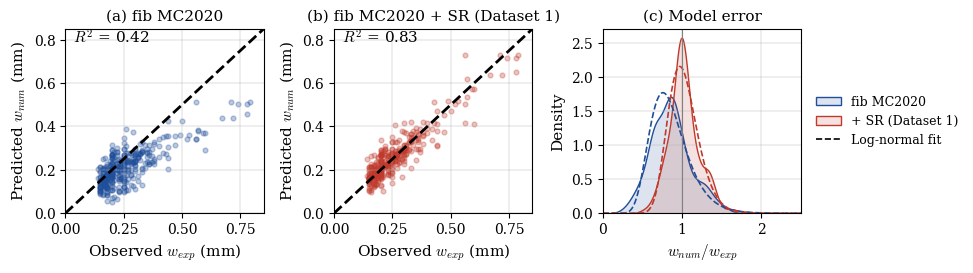

In [5]:
# Figure - fib MC2020 and fib MC2020 + SR discrepancy
fig, axs = plt.subplots(1, 3, figsize=(25 * cm, 7.2 * cm))
scatter(axs[0], results['fib MC2020'], '(a) fib MC2020', colors['original'])
scatter(axs[1], results['fib MC2020 + SR (Dataset 1)'], '(b) fib MC2020 + SR (Dataset 1)', colors['sr1'])
kde(axs[2], [('fib MC2020', results['fib MC2020'], colors['original']),
             ('+ SR (Dataset 1)', results['fib MC2020 + SR (Dataset 1)'], colors['sr1'])])
axs[2].set_title('(c) Model error', fontsize=11)
fig.tight_layout()
fig.savefig('z_fig_fib2020_sr.png', dpi=dpi, bbox_inches='tight')
plt.show()

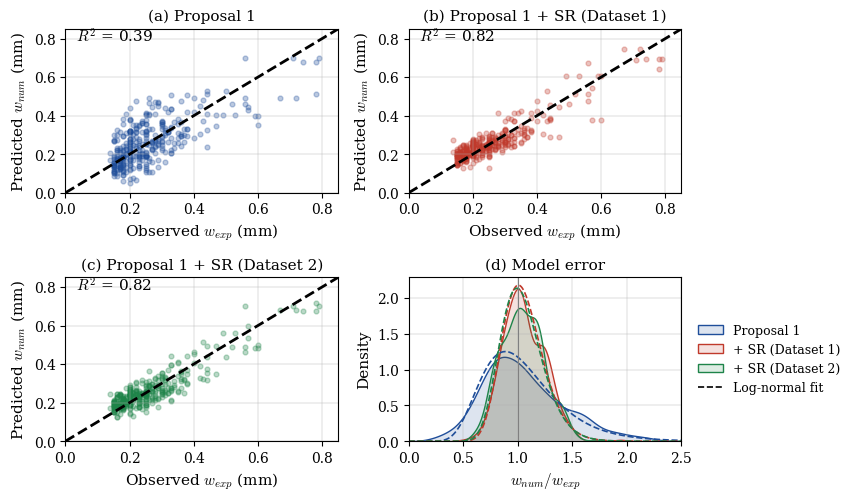

In [6]:
# Figure - Proposal 1 and Proposal 1 + SR discrepancy
fig, axs = plt.subplots(2, 2, figsize=(22 * cm, 13 * cm))
scatter(axs[0, 0], results['Proposal 1'], '(a) Proposal 1', colors['original'])
scatter(axs[0, 1], results['Proposal 1 + SR (Dataset 1)'], '(b) Proposal 1 + SR (Dataset 1)', colors['sr1'])
scatter(axs[1, 0], results['Proposal 1 + SR (Dataset 2)'], '(c) Proposal 1 + SR (Dataset 2)', colors['sr2'])
kde(axs[1, 1], [('Proposal 1', results['Proposal 1'], colors['original']),
                ('+ SR (Dataset 1)', results['Proposal 1 + SR (Dataset 1)'], colors['sr1']),
                ('+ SR (Dataset 2)', results['Proposal 1 + SR (Dataset 2)'], colors['sr2'])])
axs[1, 1].set_title('(d) Model error', fontsize=11)
fig.tight_layout()
fig.savefig('z_fig_fib2020ts_sr.png', dpi=dpi, bbox_inches='tight')
plt.show()